# Personal Stock Portfolio Analysis

Exploratory and statistical analysis of a personal stock portfolio,
covering price behavior, risk metrics, and portfolio-level performance.

**Data snapshot:** July 6, 2026

**Author:** Floris Schulmaijer

# 1. Data Import

This section loads historical stock price data that was downloaded from Yahoo Finance with the yfinance library. 12 months of daily closing prices
are loaded for the stocks in my portfolio.

The closing price is used because it is the standard reference price in finance, it reflects the final, settled price after all trading activity for the day. This makes the closing price more reliable than the opening price (which can be volatile) or intraday highs/lows (which only show temporary extremes).

### Data Snapshot

To keep this analysis reproducible, the data is downloaded once and saved as a CSV file in the `data/` folder, which is committed to this repository. The cell below always loads that frozen snapshot instead of fetching live prices. This way, the analysis and its written interpretations stay consistent no matter when or by whom this notebook is run.

The download lines are intentionally left commented out. They document how the snapshot was originally created and how to refresh it later, without ever running automatically.

In [1]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

tickers = ["AMD", "NVDA", "AEHR", "GOOGL", "SOUN", "PLAB", "SPCX"]

# One time snapshot creation, do NOT uncomment and run this unless you want to refresh the data. 
# The CSV is already included in this repo, so anyone cloning it gets the exact same frozen results automatically.
#data = yf.download(tickers, period="1y")["Close"]
#data.to_csv("data/portfolio_data.csv")

# Load frozen snapshot (this always runs)
data = pd.read_csv("data/portfolio_data.csv", index_col=0, parse_dates=True)
print(data.tail())

                 AEHR         AMD       GOOGL        NVDA       PLAB   SOUN  \
Date                                                                          
2026-06-29  94.769997  539.489990  353.649994  194.970001  31.280001  6.400   
2026-06-30  96.059998  580.909973  357.369995  200.089996  32.529999  6.470   
2026-07-01  84.430000  540.880005  361.209991  197.580002  30.309999  6.680   
2026-07-02  69.959999  517.820007  359.910004  194.830002  28.860001  6.550   
2026-07-06  75.250000  558.000000  364.429993  196.395004  29.360001  6.915   

                  SPCX  
Date                    
2026-06-29  164.190002  
2026-06-30  170.860001  
2026-07-01  157.539993  
2026-07-02  162.000000  
2026-07-06  162.199997  


# 2. Exploratory Analysis

This section explores the data visually. Raw prices, relative growth, and daily returns are plotted to understand how the portfolio
has performed over the past year.

## 2.1 Raw Stock Prices

The actual closing prices of each stock in USD are plotted here. Note that stocks with higher prices (AEHR, AMD, GOOGL) dominate
the chart. This does not mean they performed better.

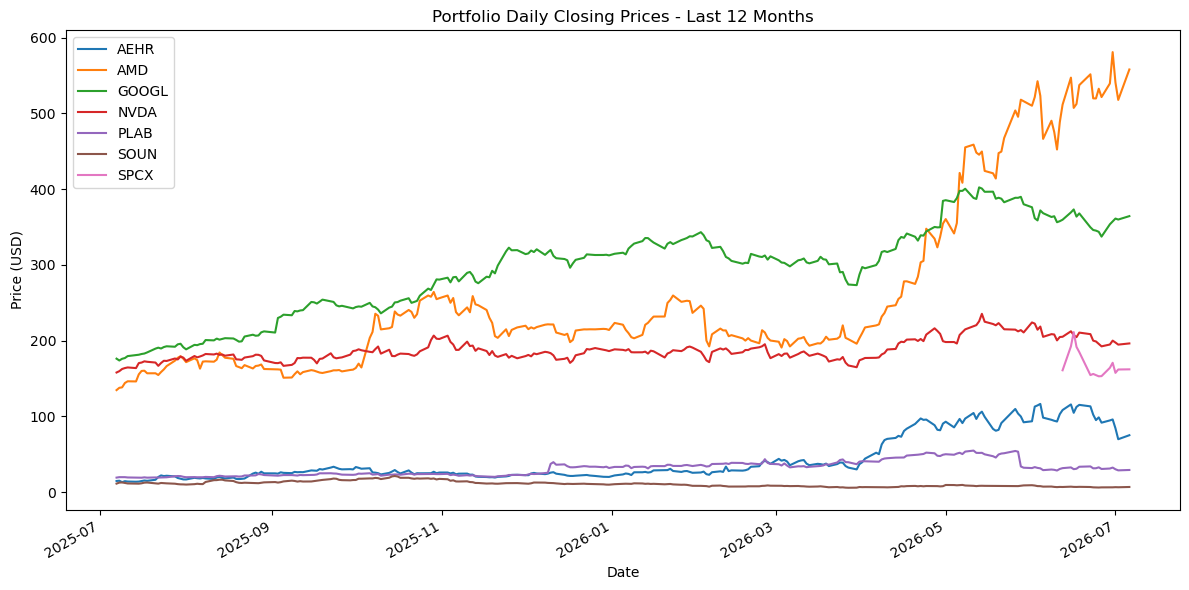

In [2]:
data.plot(figsize=(12, 6), title="Portfolio Daily Closing Prices - Last 12 Months")
plt.ylabel("Price (USD)")
plt.xlabel("Date")
plt.legend()
plt.tight_layout()
plt.show()

AMD and GOOGL dominate the chart due to their higher absolute prices, while AEHR, PLAB, and SOUN appear flat near the bottom. This is a scaling artifact, not a performance difference. Section 2.2 corrects for this using relative growth.

### 2.1.1 SpaceX — Since IPO

SpaceX went public on June 12, 2026 at $135/share, the largest IPO in history. It is plotted separately because only 2 weeks of trading history exist, making a fair comparison with other stocks impossible.

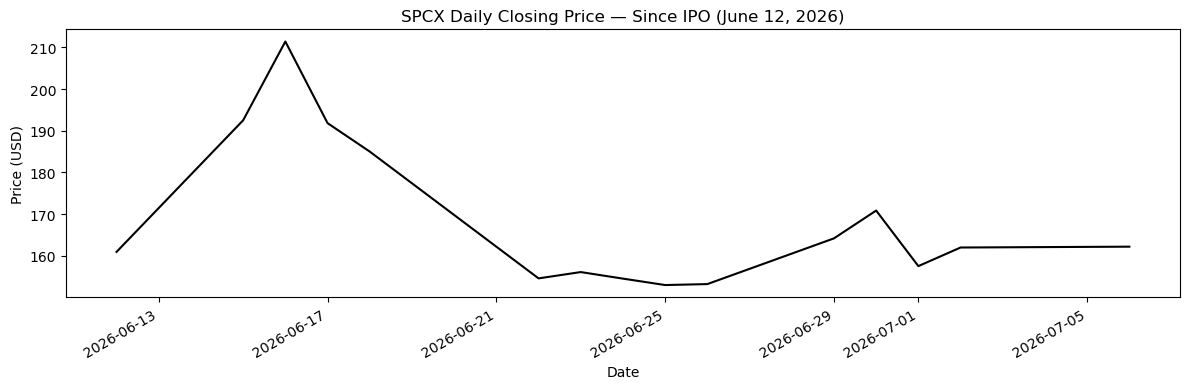

In [3]:
# One time snapshot creation, do NOT uncomment and run this unless you want to refresh the data. 
# The CSV is already included in this repo, so anyone cloning it gets the exact same frozen results automatically.
#spcx_data = yf.download("SPCX", period="1mo")["Close"]
#spcx_data.to_csv("data/spcx_data.csv")

# Load frozen snapshot (this always runs)
spcx_data = pd.read_csv("data/spcx_data.csv", index_col=0, parse_dates=True)

spcx_data.plot(figsize=(12, 4), title="SPCX Daily Closing Price — Since IPO (June 12, 2026)", color="black", legend=False)
plt.ylabel("Price (USD)")
plt.xlabel("Date")
plt.tight_layout()
plt.show()

SPCX shows classic IPO behavior: an initial rally to $210 driven by hype, followed by a sharp correction back toward its opening price as the market settles on a more realistic valuation.

## 2.2 Relative Growth

To compare stocks fairly, all prices are normalized to start at 0%. This shows the percentage gain or loss since July 2025, regardless
of the original price. This makes it clear which stock performed best. SPCX is excluded due to limited trading history.

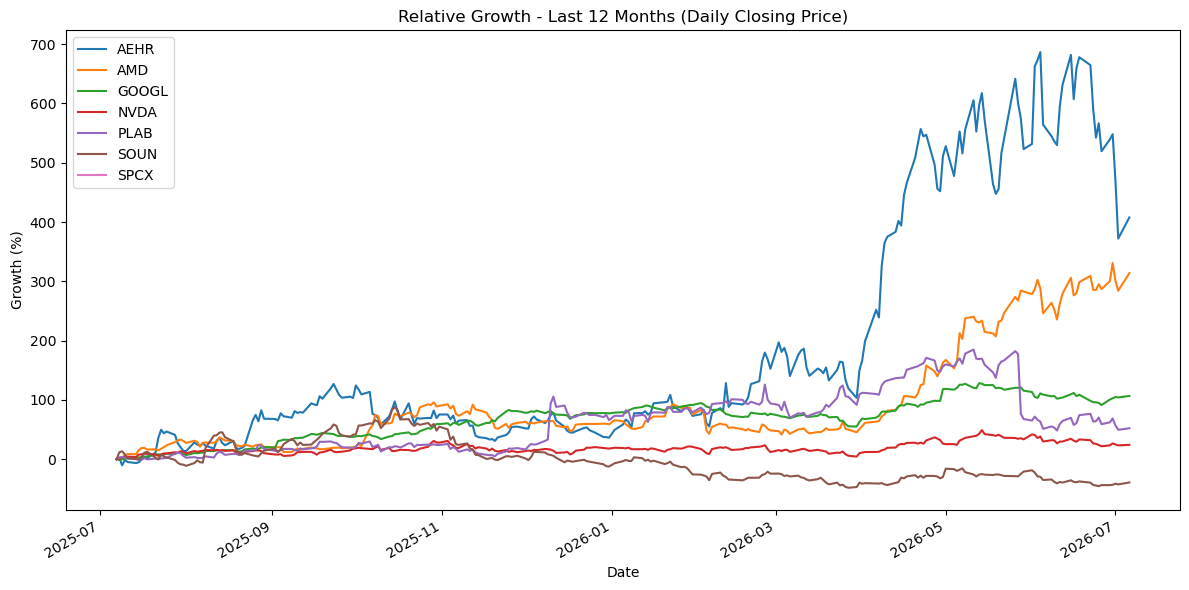

In [4]:
normalised = (data / data.iloc[0] - 1) * 100

normalised.plot(figsize=(12, 6), title="Relative Growth - Last 12 Months (Daily Closing Price)")
plt.ylabel("Growth (%)")
plt.xlabel("Date")
plt.legend()
plt.tight_layout()
plt.show()

AEHR is the clear outperformer, gaining over 700% since July 2025, followed by AMD at roughly 270%. SOUN is the only stock in negative territory, down around 20% over the same period.

## 2.3 Daily Returns

Daily returns show the percentage change in price from one day to the next. This is the foundation of all financial risk analysis. It shows not just how much a stock grew, but how volatile the journey was. (SPCX excluded)

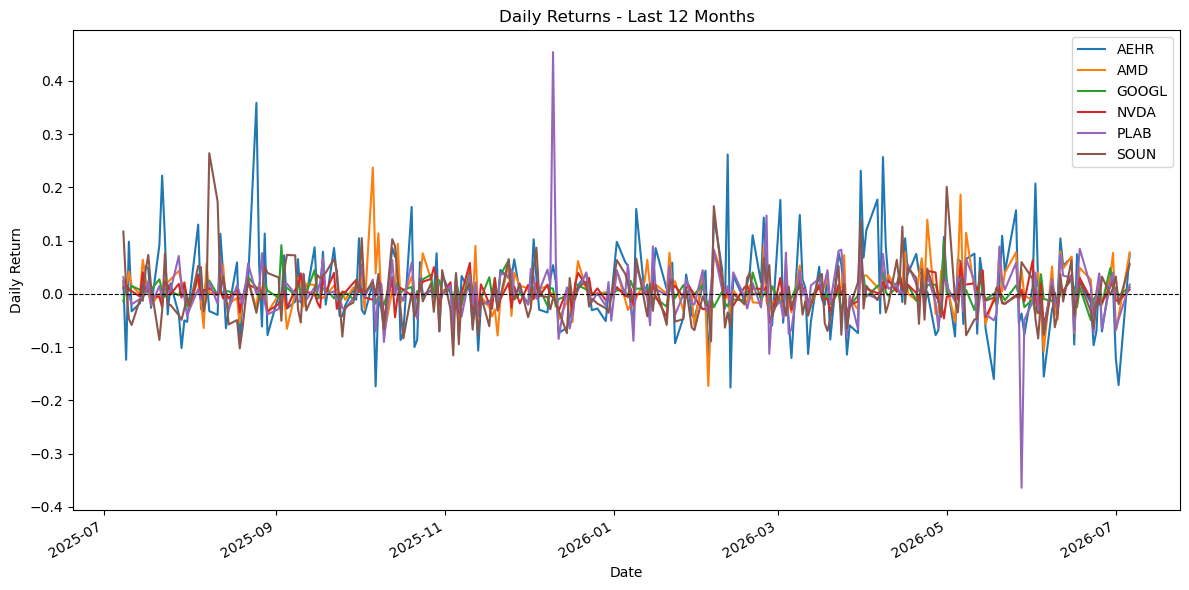

In [5]:
data_without_spcx = data.drop(columns=["SPCX"])
returns = data_without_spcx.pct_change().dropna()

returns.plot(figsize=(12, 6), title="Daily Returns - Last 12 Months")
plt.ylabel("Daily Return")
plt.xlabel("Date")
plt.legend()
plt.axhline(y=0, color="black", linewidth=0.8, linestyle="--")
plt.tight_layout()
plt.show()

AEHR shows the largest daily swings, both positive and negative, confirming it as the most volatile stock in the portfolio. GOOGL and NVDA cluster tightly around 0%, suggesting lower day-to-day risk.

## 2.4 Moving Averages

A moving average smooths out daily price noise by calculating the average price over a rolling window of days.  
- The 20-day MA reacts quickly to recent price changes.  
- The 50-day MA moves slowly and shows the long term trend.  

When the 20-day MA crosses above the 50-day MA, this is known as a **Golden Cross**. This is often interpreted as a buy signal. When it crosses below, this is a **Death Cross**, a sell signal.

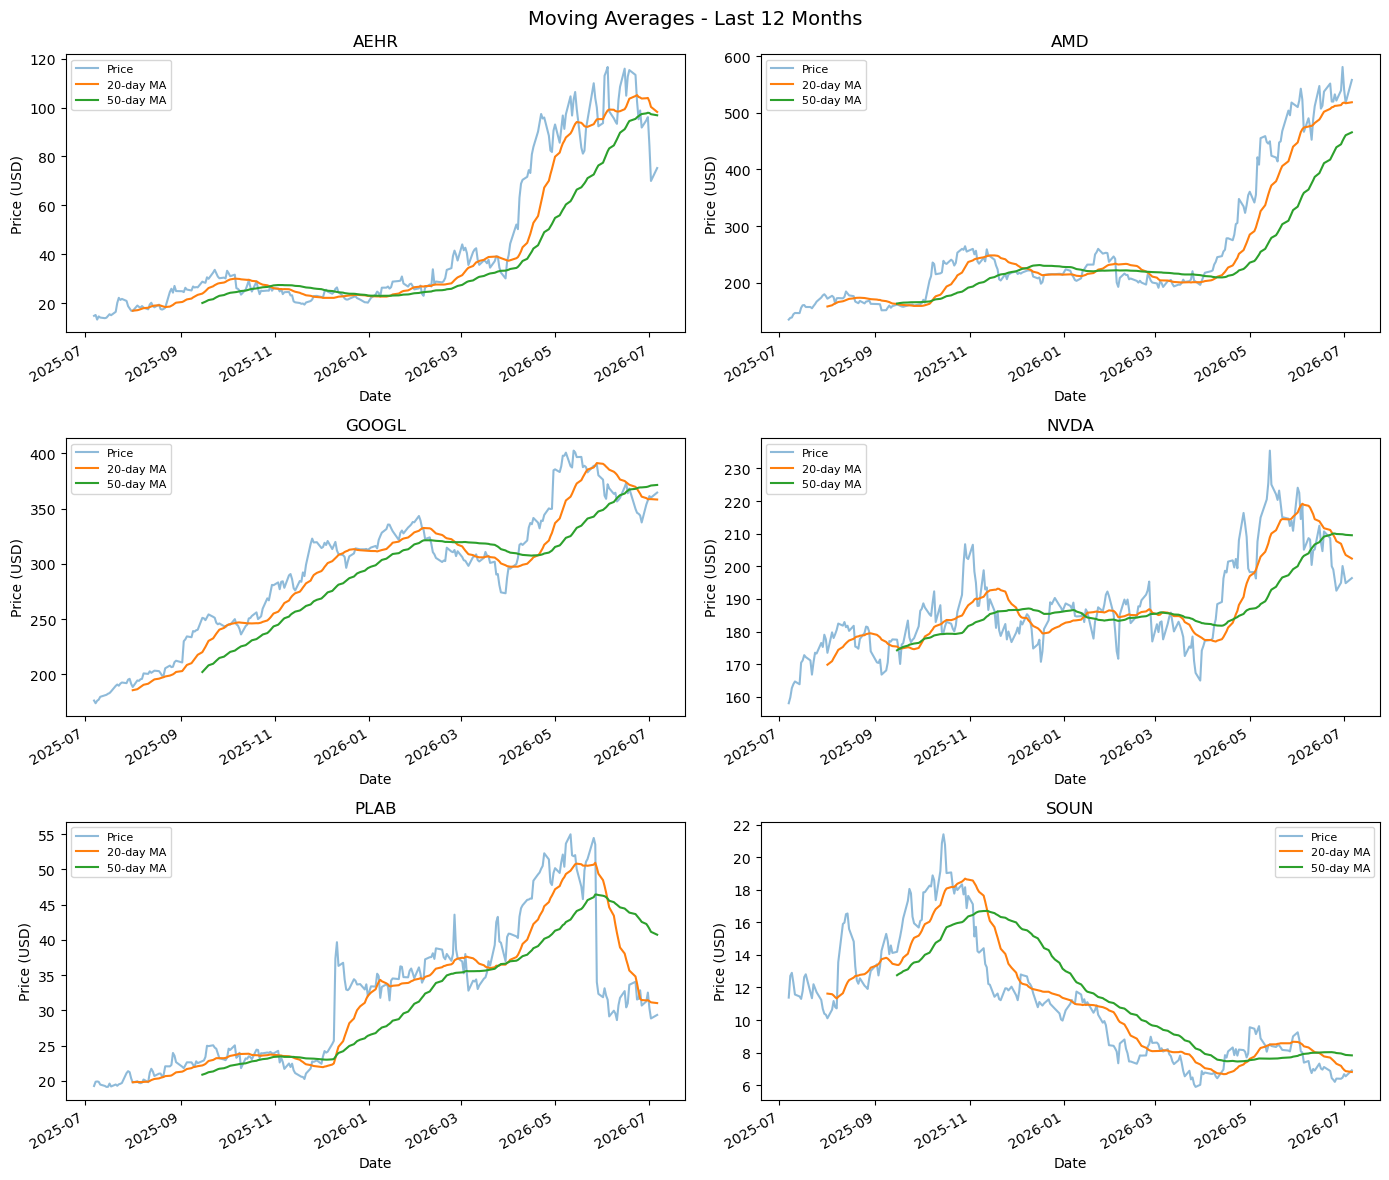

In [6]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes = axes.flatten()

for i, ticker in enumerate(data_without_spcx):
    ax = axes[i]
    data[ticker].plot(ax=ax, label="Price", alpha=0.5)
    data[ticker].rolling(20).mean().plot(ax=ax, label="20-day MA")
    data[ticker].rolling(50).mean().plot(ax=ax, label="50-day MA")
    ax.set_title(ticker)
    ax.legend(fontsize=8)
    ax.set_xlabel("Date")
    ax.set_ylabel("Price (USD)")

plt.suptitle("Moving Averages - Last 12 Months", fontsize=14)
plt.tight_layout()
plt.show()

Across the portfolio, the 20-day and 50-day moving averages track each other closely, with the 20-day MA reacting faster to price changes as expected. Several stocks (AEHR, AMD, PLAB) show periods where the 20-day MA crosses above the 50-day MA during price increases, and crosses below during declines, consistent with the Golden Cross/Death Cross pattern described above. Note that a crossover does not guarantee future direction; it simply reflects a change in short-term versus long-term trend.

## 2.5 Return Distribution

Instead of looking at returns over time, this section examines the distribution of daily returns.

A **histogram** groups returns into bins and counts how many days fall into each bin, showing the raw shape of the data.

A **KDE (Kernel Density Estimate)** is a smoothed version of the same distribution, it removes the blocky edges of the histogram to reveal the underlying shape more clearly.

A normal distribution means returns are symmetric around the mean. Fat tails mean extreme events happen more often than a normal distribution would predict, a key concept in financial risk management.

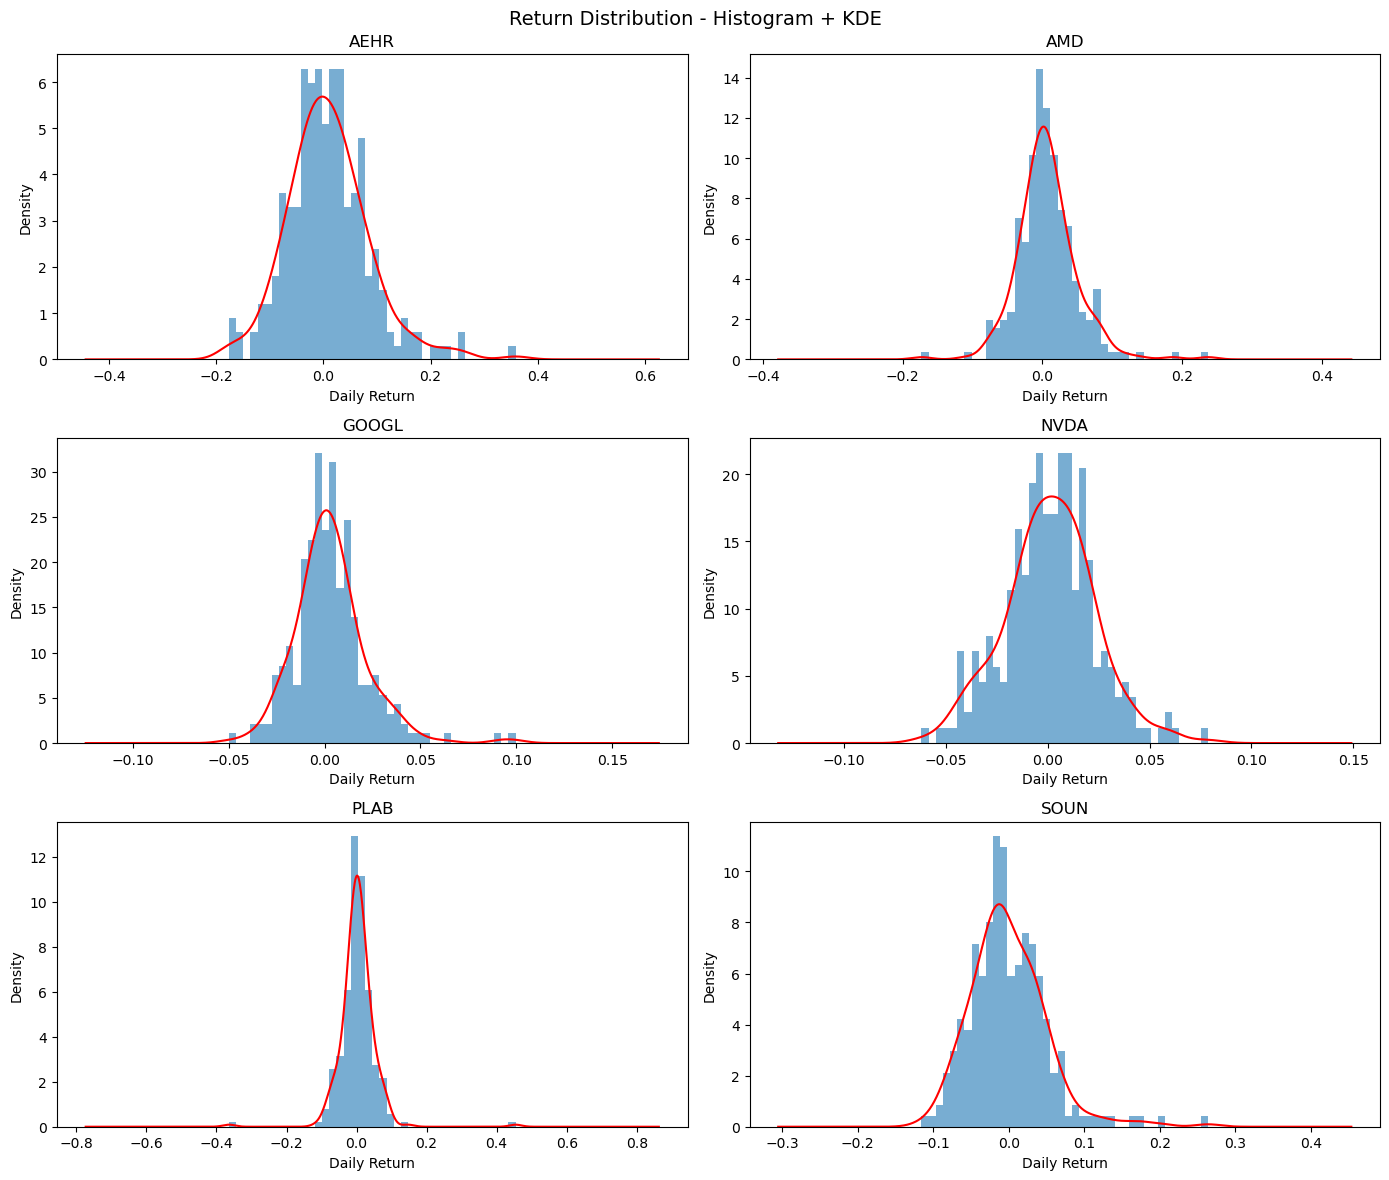

In [7]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes = axes.flatten()

for i, ticker in enumerate(returns.columns):
    ax = axes[i]
    returns[ticker].plot(kind="hist", bins=40, ax=ax, alpha=0.6, density=True)
    returns[ticker].plot(kind="kde", ax=ax, color="red")
    ax.set_title(ticker)
    ax.set_xlabel("Daily Return")
    ax.set_ylabel("Density")

plt.suptitle("Return Distribution - Histogram + KDE", fontsize=14)
plt.tight_layout()
plt.show()

Distributions vary in shape across the portfolio, with some stocks (e.g. PLAB) showing isolated extreme outliers far from the central peak, suggesting fat-tail behavior. However, visual comparison across different x-axis scales is unreliable; a formal measure such as kurtosis would quantify fat tails precisely (see Possible Extensions in the README).

# 3. Risk & Performance Metrics

This section calculates concrete numbers to measure and compare the risk and performance of each stock. While the previous section explored returns visually, here exact metrics are computed, the same numbers used by professional quant researchers and fund managers to evaluate investments objectively.

## 3.1 Volatility

Volatility is measured as the standard deviation of daily returns:

$$\sigma = \sqrt{\frac{1}{n-1} \sum_{i=1}^{n} (x_i - \bar{x})^2}$$

Where:
- $x_i$ = daily return on day $i$
- $\bar{x}$ = mean daily return
- $n$ = number of trading days

This is the sample standard deviation (dividing by $n-1$), which is also what pandas `.std()` computes.

Higher volatility means larger price swings, higher risk. Volatility is annualized by multiplying by $\sqrt{252}$, the approximate number of trading days per year, to make it comparable across different time periods.

       Daily Volatility (%)  Annualized Volatility (%)
AEHR                   7.68                     121.84
PLAB                   5.28                      83.81
SOUN                   5.07                      80.41
AMD                    4.31                      68.49
NVDA                   2.22                      35.28
GOOGL                  1.88                      29.88


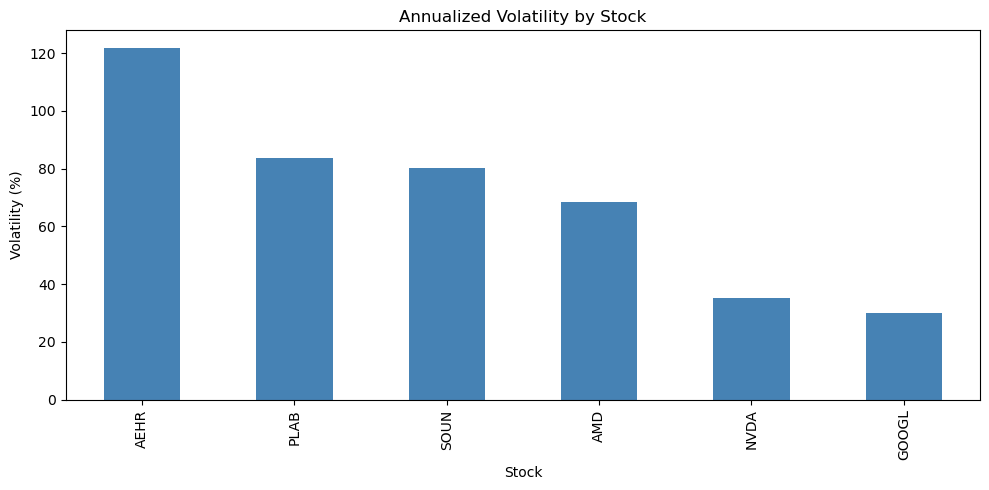

In [8]:
daily_vol = returns.std()
annual_vol = daily_vol * (252 ** 0.5) * 100

volatility_summary = pd.DataFrame({
    "Daily Volatility (%)": daily_vol * 100,
    "Annualized Volatility (%)": annual_vol
}).sort_values("Annualized Volatility (%)", ascending=False)

print(volatility_summary.round(2))

volatility_summary["Annualized Volatility (%)"].plot(kind="bar", figsize=(10, 5), color="steelblue")
plt.title("Annualized Volatility by Stock")
plt.ylabel("Volatility (%)")
plt.xlabel("Stock")
plt.tight_layout()
plt.show()

AEHR is by far the most volatile stock in the portfolio, with an annualized volatility of over 120%, more than 4x higher than GOOGL, the least volatile. PLAB and SOUN follow as the second and third most volatile, both above 80%, despite SOUN being one of the portfolio's weaker performers in absolute return. GOOGL and NVDA are the most stable, both under 40% annualized volatility, confirming the pattern observed in the daily returns plot in Section 2.3.

## 3.2 Sharpe Ratio

The Sharpe ratio measures return relative to risk. How much reward is earned for each unit of risk taken:

$$\text{Sharpe Ratio} = \frac{\bar{x} - r_f}{\sigma} \times \sqrt{252}$$

Where:
- $\bar{x}$ = mean daily return
- $r_f$ = daily risk-free rate (the return of a "safe" asset, e.g. a
  short-term government bond)
- $\sigma$ = daily volatility (standard deviation of returns)
- $\sqrt{252}$ annualizes the ratio, consistent with Section 3.1

A higher Sharpe ratio means better risk adjusted performance, more return earned per unit of risk taken. A negative Sharpe ratio means the stock underperformed the risk-free rate given the risk involved.

Risk-free rate used: 4% annually, approximating the US 3-month Treasury yield as of mid-2026.

       Sharpe Ratio
GOOGL          2.47
AMD            2.37
AEHR           1.90
PLAB           0.87
NVDA           0.68
SOUN          -0.29


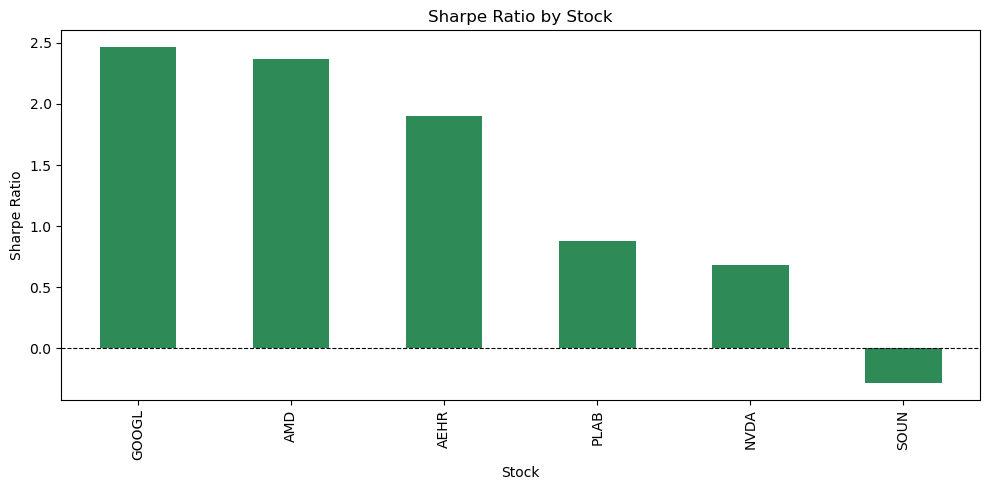

In [9]:
risk_free_rate = 0.04
daily_rf = risk_free_rate / 252

sharpe_ratio = ((returns.mean() - daily_rf) / returns.std()) * (252 ** 0.5)

sharpe_summary = pd.DataFrame({
    "Sharpe Ratio": sharpe_ratio
}).sort_values("Sharpe Ratio", ascending=False)

print(sharpe_summary.round(2))

sharpe_summary["Sharpe Ratio"].plot(kind="bar", figsize=(10, 5), color="seagreen")
plt.title("Sharpe Ratio by Stock")
plt.ylabel("Sharpe Ratio")
plt.xlabel("Stock")
plt.axhline(y=0, color="black", linewidth=0.8, linestyle="--")
plt.tight_layout()
plt.show()

GOOGL and AMD post the best risk-adjusted returns, with Sharpe ratios above 2 meaning both delivered strong returns relative to the risk taken, despite GOOGL being the least volatile stock in the portfolio (Section 3.1). AEHR still ranks third despite carrying by far the highest volatility, since its extreme returns compensate for the extra risk. NVDA stands out as a case where low volatility did not translate into a strong Sharpe ratio, its returns were too modest relative to its (already low) risk. SOUN is the only stock with a negative Sharpe ratio, confirming it underperformed even the risk-free rate given the risk involved.